In [1]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix
)
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

try:
    from imblearn.over_sampling import SMOTE
    HAS_IMBLEARN = True
except ImportError:
    HAS_IMBLEARN = False

def apply_smote(X_tr, y_tr, random_state=42):
    if HAS_IMBLEARN:
        sm = SMOTE(random_state=random_state)
        return sm.fit_resample(X_tr, y_tr)
    rng = np.random.RandomState(random_state)
    X_arr = X_tr.values if isinstance(X_tr, pd.DataFrame) else np.asarray(X_tr)
    y_arr = np.asarray(y_tr)
    classes, counts = np.unique(y_arr, return_counts=True)
    maj_cls, min_cls = classes[np.argmax(counts)], classes[np.argmin(counts)]
    n_needed = counts.max() - counts.min()
    X_min = X_arr[y_arr == min_cls]
    nn = NearestNeighbors(n_neighbors=6).fit(X_min)
    _, indices = nn.kneighbors(X_min)
    synth = []
    for _ in range(n_needed):
        idx = rng.randint(0, len(X_min))
        nn_idx = indices[idx, rng.randint(1, 6)]
        alpha = rng.rand()
        synth.append(X_min[idx] + alpha * (X_min[nn_idx] - X_min[idx]))
    X_res = np.vstack([X_arr, np.array(synth)])
    y_res = np.concatenate([y_arr, np.full(n_needed, min_cls)])
    if isinstance(X_tr, pd.DataFrame):
        X_res = pd.DataFrame(X_res, columns=X_tr.columns)
    return X_res, y_res

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
print("Setup complete!")

Setup complete!


**Part 1 – Q1 : Target Variable Distribution & Class Balance**


In [2]:
df_us = pd.read_csv('us_masters_admission_competitiveness - LMS.csv')
print("Dataset Shape:", df_us.shape)

target_counts = df_us['admission_competitiveness'].value_counts()
target_pct = df_us['admission_competitiveness'].value_counts(normalize=True) * 100
print(pd.DataFrame({'Count': target_counts, 'Percentage (%)': target_pct.round(2)}))

plt.figure(figsize=(6, 4))
sns.countplot(data=df_us, x='admission_competitiveness', palette=['#d9534f', '#2e8b57'])
plt.title('Target Class Distribution (70:30 Imbalance)')
plt.xticks([0, 1], ['0: Non-Competitive (3640)', '1: Competitive (1560)'])
plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'us_masters_admission_competitiveness - LMS.csv'

**Part 1 – Q1 : Categorical Features Analysis**



Competitiveness Rate (%) by ug_university_tier:
admission_competitiveness      0      1
ug_university_tier                     
Tier 1                     52.13  47.87
Tier 2                     67.57  32.43
Tier 3                     87.87  12.13

Competitiveness Rate (%) by target_university_ranking_band:
admission_competitiveness           0      1
target_university_ranking_band              
Above 100                       71.41  28.59
Top 100                         68.29  31.71
Top 20                          70.17  29.83
Top 50                          70.75  29.25

Competitiveness Rate (%) by application_round:
admission_competitiveness      0      1
application_round                      
Fall                       69.37  30.63
Spring                     72.35  27.65

Competitiveness Rate (%) by visa_dependency:
admission_competitiveness      0      1
visa_dependency                        
No                         68.10  31.90
Yes                        70.17  29.83


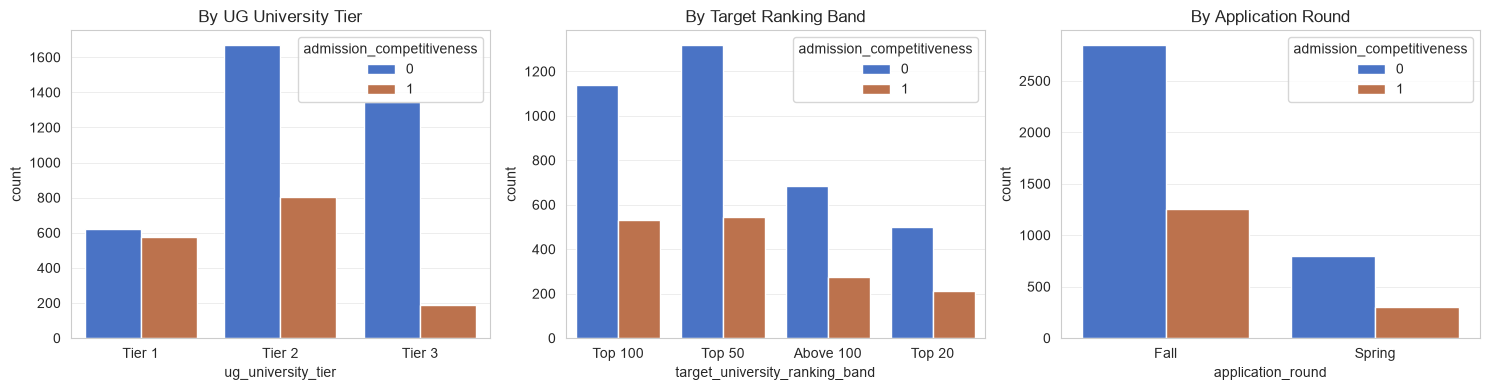

In [30]:
cat_cols_eda = ['ug_university_tier', 'target_university_ranking_band', 'application_round', 'visa_dependency']
for col in cat_cols_eda:
    ct = pd.crosstab(df_us[col], df_us['admission_competitiveness'], normalize='index') * 100
    print(f"\nCompetitiveness Rate (%) by {col}:")
    print(ct.round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=df_us, x='ug_university_tier', hue='admission_competitiveness', order=['Tier 1', 'Tier 2', 'Tier 3'], ax=axes[0])
axes[0].set_title('By UG University Tier')

sns.countplot(data=df_us, x='target_university_ranking_band', hue='admission_competitiveness', ax=axes[1])
axes[1].set_title('By Target Ranking Band')

sns.countplot(data=df_us, x='application_round', hue='admission_competitiveness', ax=axes[2])
axes[2].set_title('By Application Round')

plt.tight_layout()
plt.show()

**Part 1 – Q1 : Competitive vs. Non-Competitive Student Profile 

Mean Feature Values by Target Class (0 = Non-Competitive, 1 = Competitive):
admission_competitiveness         0        1
sop_quality_score             5.971    6.969
field_alignment_score         6.139    7.024
internship_relevance_score    5.842    6.670
lor_strength_score            5.822    6.551
resume_strength_score         6.329    6.826
ug_gpa                        7.289    7.390
gre_quant                   156.751  157.201
number_of_backlogs            0.979    0.696


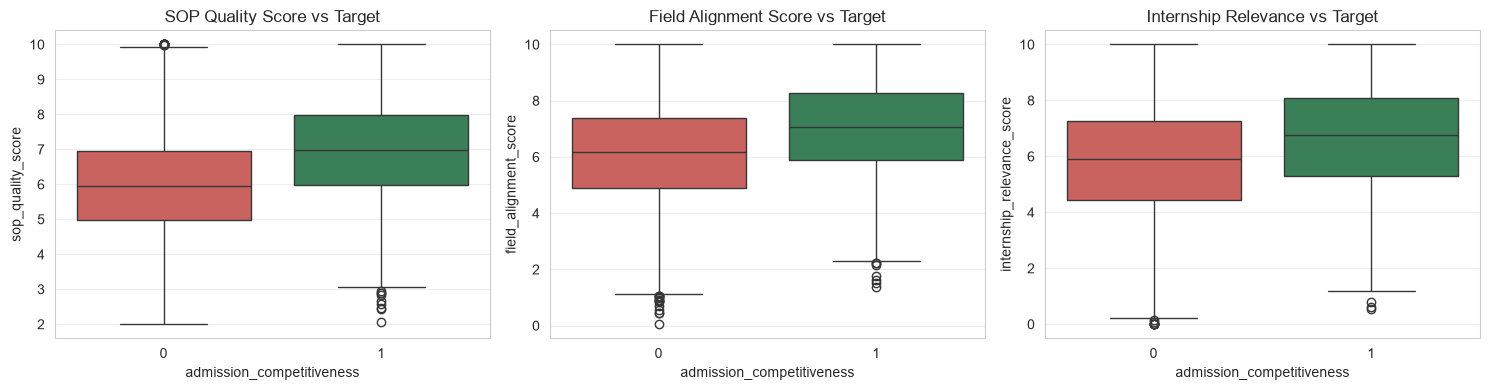

In [31]:
num_compare = [
    'sop_quality_score', 'field_alignment_score', 'internship_relevance_score',
    'lor_strength_score', 'resume_strength_score', 'ug_gpa', 'gre_quant', 'number_of_backlogs'
]
print("Mean Feature Values by Target Class (0 = Non-Competitive, 1 = Competitive):")
print(df_us.groupby('admission_competitiveness')[num_compare].mean().T.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=df_us, x='admission_competitiveness', y='sop_quality_score', palette=['#d9534f', '#2e8b57'], ax=axes[0])
axes[0].set_title('SOP Quality Score vs Target')

sns.boxplot(data=df_us, x='admission_competitiveness', y='field_alignment_score', palette=['#d9534f', '#2e8b57'], ax=axes[1])
axes[1].set_title('Field Alignment Score vs Target')

sns.boxplot(data=df_us, x='admission_competitiveness', y='internship_relevance_score', palette=['#d9534f', '#2e8b57'], ax=axes[2])
axes[2].set_title('Internship Relevance vs Target')

plt.tight_layout()
plt.show()

**Part 1 – Q2 (a): Data Cleaning


In [32]:
df_clean = df_us.copy()
missing_us = df_clean.isnull().sum()
print("Missing Values Before Cleaning:")
print(missing_us[missing_us > 0])

# Stratified split first so imputation fits strictly on training data
train_idx, test_idx = train_test_split(df_clean.index, test_size=0.20, random_state=42, stratify=df_clean['admission_competitiveness'])
num_missing_cols = [
    'academic_consistency_score', 'gre_awa', 'internship_relevance_score',
    'lor_strength_score', 'resume_strength_score'
]
for col in num_missing_cols:
    med_val = df_clean.loc[train_idx, col].median()
    df_clean.loc[train_idx, col] = df_clean.loc[train_idx, col].fillna(med_val)
    df_clean.loc[test_idx, col] = df_clean.loc[test_idx, col].fillna(med_val)

print("Remaining Missing Values:", df_clean.isnull().sum().sum())

Missing Values Before Cleaning:
academic_consistency_score    228
gre_awa                       220
internship_relevance_score    247
lor_strength_score            219
resume_strength_score         238
dtype: int64
Remaining Missing Values: 0


**Part 1 – Q2 (b): Feature Handling


In [33]:
df_clean.drop(columns=['student_id'], inplace=True)

df_clean['ug_university_tier'] = df_clean['ug_university_tier'].map({'Tier 3': 1, 'Tier 2': 2, 'Tier 1': 3})
df_clean['target_university_ranking_band'] = df_clean['target_university_ranking_band'].map({'Above 100': 1, 'Top 100': 2, 'Top 50': 3, 'Top 20': 4})
df_clean['visa_dependency'] = df_clean['visa_dependency'].map({'No': 0, 'Yes': 1})

nominal_cols = ['ug_major', 'english_test_type', 'intended_specialization', 'application_round', 'preferred_application_city']
df_encoded = pd.get_dummies(df_clean, columns=nominal_cols, drop_first=True, dtype=int)

X_train = df_encoded.loc[train_idx].drop(columns=['admission_competitiveness'])
y_train = df_encoded.loc[train_idx, 'admission_competitiveness']
X_test = df_encoded.loc[test_idx].drop(columns=['admission_competitiveness'])
y_test = df_encoded.loc[test_idx, 'admission_competitiveness']

print("Encoded Train Shape:", X_train.shape, "| Test Shape:", X_test.shape)

Encoded Train Shape: (4160, 43) | Test Shape: (1040, 43)


**Part 1 – Q2 (c): Feature Scaling


In [34]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)
print("Scaling completed (Train Mean ~ 0, Std ~ 1). Sample mean:", round(X_train_scaled.mean().mean(), 4))

Scaling completed (Train Mean ~ 0, Std ~ 1). Sample mean: -0.0


**Part 1 – Q2 (d): Feature Selection


Top 10 Most Influential Features:
sop_quality_score             0.1080
field_alignment_score         0.0788
lor_strength_score            0.0777
ug_university_tier            0.0637
internship_relevance_score    0.0636
resume_strength_score         0.0550
academic_consistency_score    0.0466
ug_gpa                        0.0370
career_goal_clarity_score     0.0367
work_experience_months        0.0366
dtype: float64


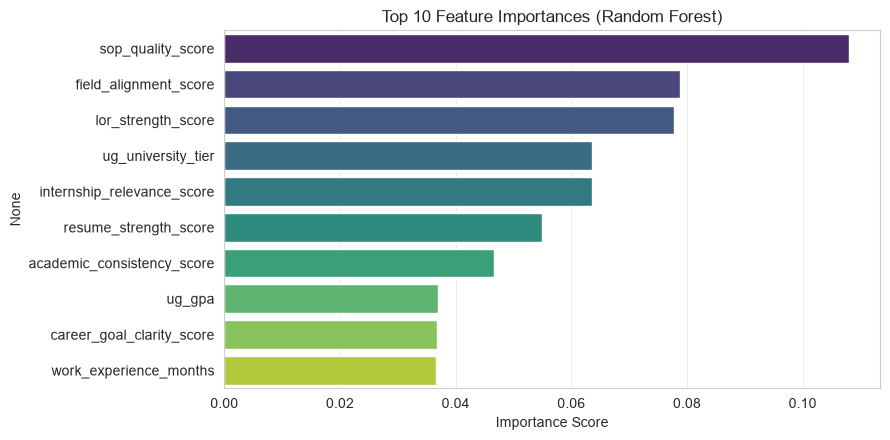

In [35]:
rf_selector = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf_selector.fit(X_train_scaled, y_train)

feat_imp = pd.Series(rf_selector.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print("Top 10 Most Influential Features:")
print(feat_imp.head(10).round(4))

plt.figure(figsize=(9, 4.5))
sns.barplot(x=feat_imp.head(10).values, y=feat_imp.head(10).index, palette='viridis')
plt.title('Top 10 Feature Importances (Random Forest)')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

**Part 1 – Q3 (1/3): Logistic Regression**


In [36]:
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)
print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


**Part 1 – Q3 (2/3): Decision Tree Classifier**


In [37]:
dt_model = DecisionTreeClassifier(max_depth=8, min_samples_split=15, random_state=42)
dt_model.fit(X_train_scaled, y_train)
print("Decision Tree Classifier trained successfully.")

Decision Tree Classifier trained successfully.


**Part 1 – Q3 (3/3): Random Forest Classifier**


In [38]:
rf_model = RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1)
rf_model.fit(X_train_scaled, y_train)
print("Random Forest Classifier trained successfully.")

Random Forest Classifier trained successfully.


**Part 1 – Q4(A) : Evaluate All Models**


In [39]:
def get_metrics(name, model, X_te, y_te):
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1]
    return {
        'Model': name,
        'Accuracy': round(accuracy_score(y_te, y_pred), 4),
        'Precision': round(precision_score(y_te, y_pred), 4),
        'Recall': round(recall_score(y_te, y_pred), 4),
        'F1-Score': round(f1_score(y_te, y_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_te, y_prob), 4)
    }, confusion_matrix(y_te, y_pred)

baseline_models = {'Logistic Regression': lr_model, 'Decision Tree': dt_model, 'Random Forest': rf_model}
results_list = []
cms = {}

for name, m in baseline_models.items():
    res, cm = get_metrics(name, m, X_test_scaled, y_test)
    results_list.append(res)
    cms[name] = cm
    print(res)

{'Model': 'Logistic Regression', 'Accuracy': 0.8058, 'Precision': 0.6923, 'Recall': 0.6346, 'F1-Score': 0.6622, 'ROC-AUC': 0.8653}
{'Model': 'Decision Tree', 'Accuracy': 0.7308, 'Precision': 0.5559, 'Recall': 0.5096, 'F1-Score': 0.5318, 'ROC-AUC': 0.7438}
{'Model': 'Random Forest', 'Accuracy': 0.7933, 'Precision': 0.8012, 'Recall': 0.4135, 'F1-Score': 0.5455, 'ROC-AUC': 0.847}


**Part 1 – Q4(B): Consolidated Comparison Table (Baseline Models)**


In [40]:
baseline_df = pd.DataFrame(results_list)
print(baseline_df.to_string(index=False))

              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression    0.8058     0.6923  0.6346    0.6622   0.8653
      Decision Tree    0.7308     0.5559  0.5096    0.5318   0.7438
      Random Forest    0.7933     0.8012  0.4135    0.5455   0.8470


**Part 1 – Q4 (C): Handle Class Imbalance Using SMOTE & Retrain**


In [41]:
X_train_smote, y_train_smote = apply_smote(X_train_scaled, y_train, random_state=42)
print("Balanced Train Class Counts:", pd.Series(y_train_smote).value_counts().to_dict())

lr_smote = LogisticRegression(max_iter=1000, random_state=42)
lr_smote.fit(X_train_smote, y_train_smote)
res_lr_s, cm_lr_s = get_metrics('Logistic Regression (SMOTE)', lr_smote, X_test_scaled, y_test)
results_list.append(res_lr_s)
cms['Logistic Regression (SMOTE)'] = cm_lr_s

rf_smote = RandomForestClassifier(n_estimators=250, max_depth=14, random_state=42, n_jobs=-1)
rf_smote.fit(X_train_smote, y_train_smote)
res_rf_s, cm_rf_s = get_metrics('Random Forest (SMOTE)', rf_smote, X_test_scaled, y_test)
results_list.append(res_rf_s)
cms['Random Forest (SMOTE)'] = cm_rf_s

print("Retrained SMOTE models successfully.")

Balanced Train Class Counts: {0: 2912, 1: 2912}
Retrained SMOTE models successfully.


**Part 1 – Q4 (D): Best-Performing Model Selection**


=== Final Consolidated Model Comparison Table ===
                      Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression (SMOTE)    0.7798     0.6015  0.7885    0.6824   0.8638
        Logistic Regression    0.8058     0.6923  0.6346    0.6622   0.8653
      Random Forest (SMOTE)    0.7875     0.6553  0.6154    0.6347   0.8401
              Random Forest    0.7933     0.8012  0.4135    0.5455   0.8470
              Decision Tree    0.7308     0.5559  0.5096    0.5318   0.7438


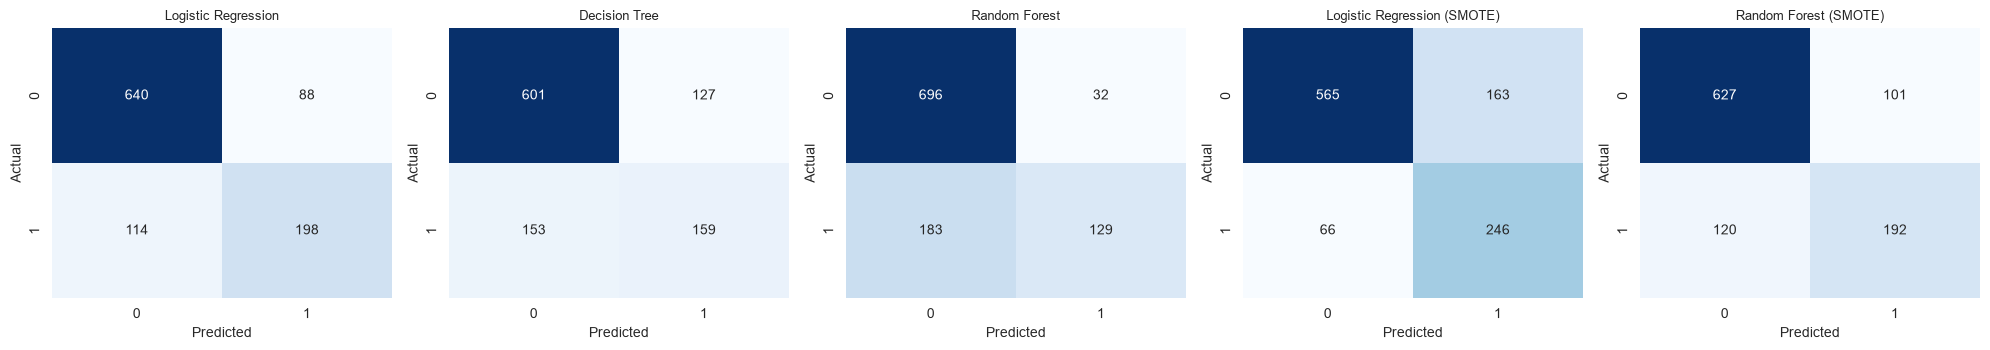

In [42]:
final_comparison_df = pd.DataFrame(results_list).sort_values(by='F1-Score', ascending=False)
print("=== Final Consolidated Model Comparison Table ===")
print(final_comparison_df.to_string(index=False))

fig, axes = plt.subplots(1, 5, figsize=(20, 3.6))
for ax, (m_name, cm) in zip(axes, cms.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(m_name, fontsize=9)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

**Part 2 – Q1 (A): Numerical Distributions (Engagement & Ordering Behavior)**


Zomato Shape: (3640, 22)
                               count     mean      50%      std    min  \
app_opens_per_month           3640.0    31.42    27.65    21.87    1.0   
avg_session_duration_minutes  3640.0     8.98     8.59     4.15    1.0   
orders_per_month              3640.0     8.17     6.65     6.54    0.0   
avg_order_value               3515.0   306.52   294.03    97.30  120.0   
monthly_food_spend            3640.0  2955.97  1923.75  2938.19    0.0   
discount_usage_rate           3523.0     0.37     0.35     0.17    0.0   
days_since_last_order         3640.0    15.50     9.05    16.78    0.0   

                                   max  
app_opens_per_month              92.86  
avg_session_duration_minutes     23.50  
orders_per_month                 28.83  
avg_order_value                 728.53  
monthly_food_spend            15637.17  
discount_usage_rate               0.97  
days_since_last_order            86.27  


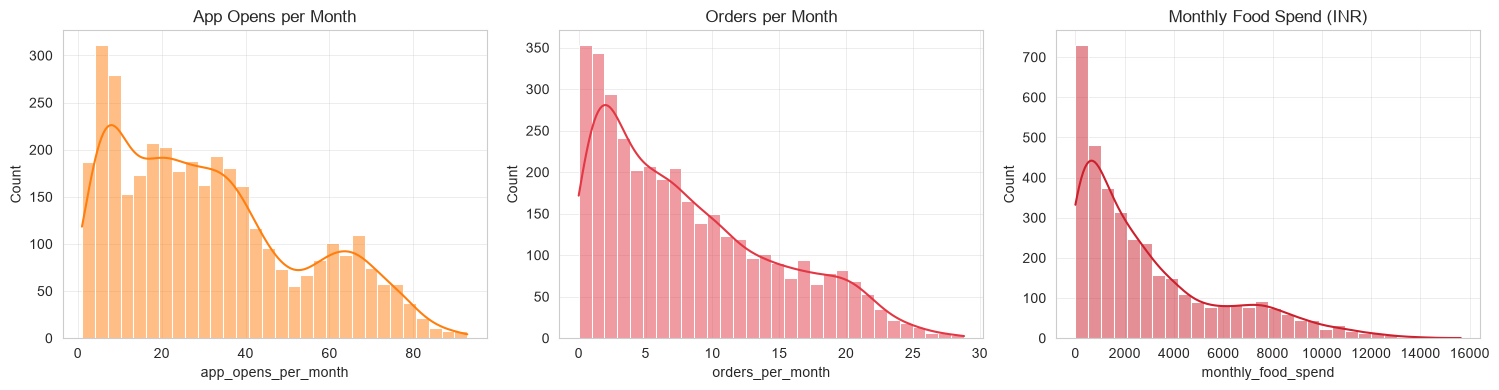

In [43]:
df_zom = pd.read_csv('zomato_user_data - LMS.csv')
print("Zomato Shape:", df_zom.shape)

num_eda_z = [
    'app_opens_per_month', 'avg_session_duration_minutes', 'orders_per_month',
    'avg_order_value', 'monthly_food_spend', 'discount_usage_rate', 'days_since_last_order'
]
print(df_zom[num_eda_z].describe().T[['count', 'mean', '50%', 'std', 'min', 'max']].round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df_zom['app_opens_per_month'], bins=30, kde=True, color='#ff7f0e', ax=axes[0])
axes[0].set_title('App Opens per Month')

sns.histplot(df_zom['orders_per_month'], bins=30, kde=True, color='#e23744', ax=axes[1])
axes[1].set_title('Orders per Month')

sns.histplot(df_zom['monthly_food_spend'], bins=30, kde=True, color='#cb202d', ax=axes[2])
axes[2].set_title('Monthly Food Spend (INR)')

plt.tight_layout()
plt.show()

**Part 2 – Q1 (B): Categorical Variables Analysis**



Value Counts for device_type:
device_type
Android    2864
iOS         776
Name: count, dtype: int64

Value Counts for subscription_status_clean:
subscription_status_clean
Regular (Non-Gold)    2435
Zomato Gold           1205
Name: count, dtype: int64

Value Counts for user_segment_label:
user_segment_label
Returning    1589
Long-Term    1107
New           944
Name: count, dtype: int64

Value Counts for city:
city
Kolkata      542
Hyderabad    540
Mumbai       540
Pune         535
Delhi        498
Chennai      498
Bangalore    487
Name: count, dtype: int64


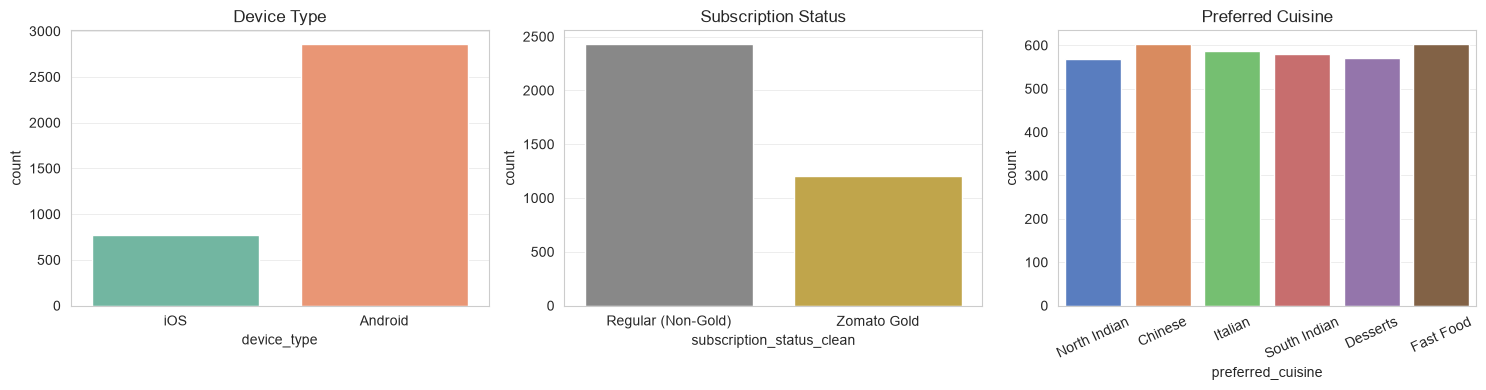

In [44]:
df_zom_viz = df_zom.copy()
df_zom_viz['subscription_status_clean'] = df_zom_viz['subscription_status'].fillna('Regular (Non-Gold)')

for col in ['device_type', 'subscription_status_clean', 'user_segment_label', 'city']:
    print(f"\nValue Counts for {col}:")
    print(df_zom_viz[col].value_counts())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=df_zom_viz, x='device_type', palette='Set2', ax=axes[0])
axes[0].set_title('Device Type')

sns.countplot(data=df_zom_viz, x='subscription_status_clean', palette=['#888888', '#d4af37'], ax=axes[1])
axes[1].set_title('Subscription Status')

sns.countplot(data=df_zom_viz, x='preferred_cuisine', palette='muted', ax=axes[2])
axes[2].set_title('Preferred Cuisine')
axes[2].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

**Part 2 – Q1 (C&D): Key Observations on Usage Patterns**


Mean Engagement by Subscription Status:
                           app_opens_per_month  avg_session_duration_minutes  \
subscription_status_clean                                                      
Regular (Non-Gold)                       31.41                          8.99   
Zomato Gold                              31.43                          8.96   

                           orders_per_month  avg_order_value  \
subscription_status_clean                                      
Regular (Non-Gold)                     8.17           306.96   
Zomato Gold                            8.17           305.63   

                           monthly_food_spend  discount_usage_rate  \
subscription_status_clean                                            
Regular (Non-Gold)                    2954.47                 0.37   
Zomato Gold                           2958.98                 0.37   

                           days_since_last_order  
subscription_status_clean                         

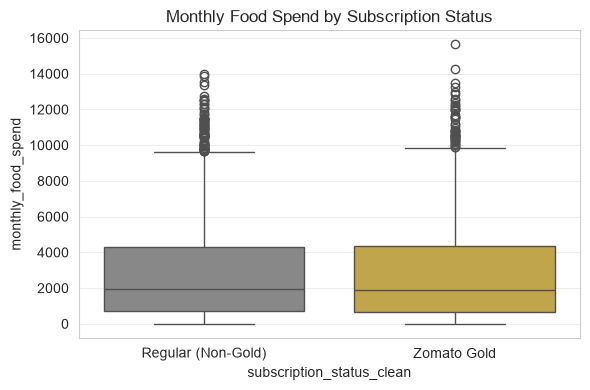

In [45]:
print("Mean Engagement by Subscription Status:")
print(df_zom_viz.groupby('subscription_status_clean')[num_eda_z].mean().round(2))

plt.figure(figsize=(6, 4))
sns.boxplot(data=df_zom_viz, x='subscription_status_clean', y='monthly_food_spend', palette=['#888888', '#d4af37'])
plt.title('Monthly Food Spend by Subscription Status')
plt.tight_layout()
plt.show()

**Part 2 – Q2 (a): Data Quality Analysis


In [46]:
df_z_clean = df_zom.copy()
print("Exact Duplicates Found:", df_z_clean.duplicated().sum())
df_z_clean = df_z_clean.drop_duplicates().reset_index(drop=True)
print("Shape After Deduplication:", df_z_clean.shape)

print("\nMissing Values After Deduplication:")
print(df_z_clean.isnull().sum()[df_z_clean.isnull().sum() > 0])

df_z_clean['subscription_status'] = df_z_clean['subscription_status'].fillna('No Gold')
df_z_clean['preferred_cuisine'] = df_z_clean['preferred_cuisine'].fillna('Unknown')
for col in ['avg_order_value', 'discount_usage_rate', 'avg_delivery_time_minutes']:
    df_z_clean[col] = df_z_clean[col].fillna(df_z_clean[col].median())

print("Remaining Missing Values:", df_z_clean.isnull().sum().sum())

Exact Duplicates Found: 53
Shape After Deduplication: (3587, 22)

Missing Values After Deduplication:
subscription_status          2405
preferred_cuisine             128
avg_order_value               123
discount_usage_rate           115
avg_delivery_time_minutes     115
dtype: int64
Remaining Missing Values: 0


**Part 2 – Q2 (b): Outlier Detection


In [47]:
num_cols_z = df_z_clean.select_dtypes(include=np.number).columns.tolist()
outlier_summary = []
for col in num_cols_z:
    Q1 = df_z_clean[col].quantile(0.25)
    Q3 = df_z_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = ((df_z_clean[col] < (Q1 - 1.5 * IQR)) | (df_z_clean[col] > (Q3 + 1.5 * IQR))).sum()
    outlier_summary.append({'Feature': col, 'IQR_Outliers': outliers, 'Outlier_%': round(outliers / len(df_z_clean) * 100, 2)})

print(pd.DataFrame(outlier_summary).sort_values(by='IQR_Outliers', ascending=False).to_string(index=False))

                      Feature  IQR_Outliers  Outlier_%
        days_since_last_order           384      10.71
           monthly_food_spend           121       3.37
       customer_support_chats            82       2.29
          weekend_order_ratio            44       1.23
              avg_order_value            34       0.95
browse_sessions_without_order            32       0.89
          discount_usage_rate            26       0.72
      late_night_orders_ratio            21       0.59
             app_rating_given            20       0.56
    avg_delivery_time_minutes            20       0.56
       peak_hour_orders_ratio            19       0.53
           promo_orders_ratio            16       0.45
      order_cancellation_rate            14       0.39
 avg_session_duration_minutes             9       0.25
             orders_per_month             8       0.22
          app_opens_per_month             0       0.00


**Part 2 – Q2 (c): Correlation Analysis

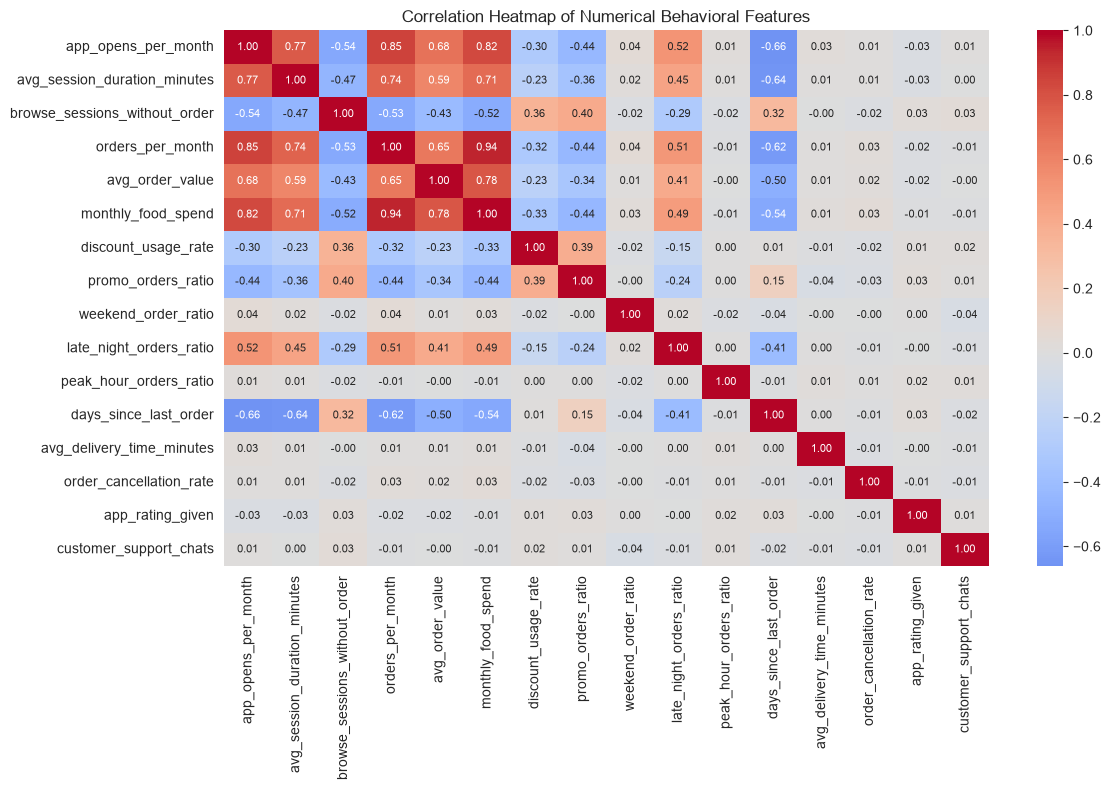

In [48]:
plt.figure(figsize=(12, 8))
corr_matrix_z = df_z_clean[num_cols_z].corr()
sns.heatmap(corr_matrix_z, annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 8})
plt.title('Correlation Heatmap of Numerical Behavioral Features')
plt.tight_layout()
plt.show()

**Part 2 – Q3 (a): Standardize Numerical Features**


In [49]:
scaler_z = StandardScaler()
X_z_scaled = scaler_z.fit_transform(df_z_clean[num_cols_z])
print("Standardized Matrix Shape:", X_z_scaled.shape)

Standardized Matrix Shape: (3587, 16)


**Part 2 – Q3 (b): Apply PCA & Select Components (90%–95% Variance)**


Components for >=90% variance: 11 (91.64%)
Components for >=95% variance: 13 (96.97%)


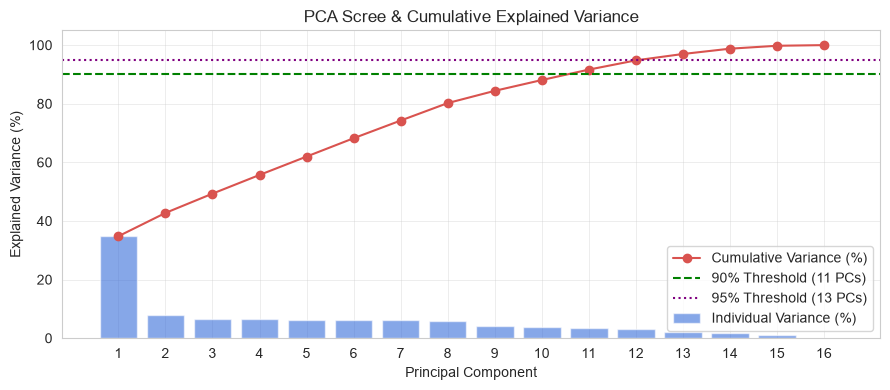

In [50]:
pca_full = PCA(random_state=42)
pca_full.fit(X_z_scaled)

explained_var = pca_full.explained_variance_ratio_
cum_var = np.cumsum(explained_var)

n_comp_90 = int(np.argmax(cum_var >= 0.90) + 1)
n_comp_95 = int(np.argmax(cum_var >= 0.95) + 1)
print(f"Components for >=90% variance: {n_comp_90} ({cum_var[n_comp_90-1]*100:.2f}%)")
print(f"Components for >=95% variance: {n_comp_95} ({cum_var[n_comp_95-1]*100:.2f}%)")

pca = PCA(n_components=n_comp_90, random_state=42)
X_z_pca = pca.fit_transform(X_z_scaled)

plt.figure(figsize=(9, 4))
plt.bar(range(1, len(explained_var) + 1), explained_var * 100, alpha=0.6, label='Individual Variance (%)')
plt.plot(range(1, len(cum_var) + 1), cum_var * 100, marker='o', color='#d9534f', label='Cumulative Variance (%)')
plt.axhline(90, color='green', linestyle='--', label='90% Threshold (11 PCs)')
plt.axhline(95, color='purple', linestyle=':', label='95% Threshold (13 PCs)')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance (%)')
plt.title('PCA Scree & Cumulative Explained Variance')
plt.xticks(range(1, len(explained_var) + 1))
plt.legend()
plt.tight_layout()
plt.show()

**Part 2 – Q3 (c): Variance Explained by Selected Components**


In [51]:
loadings = pd.DataFrame(pca.components_[:2].T, columns=['PC1_Loading', 'PC2_Loading'], index=num_cols_z)
print(loadings.round(3))

                               PC1_Loading  PC2_Loading
app_opens_per_month                  0.390        0.073
avg_session_duration_minutes         0.354        0.141
browse_sessions_without_order       -0.274        0.281
orders_per_month                     0.391        0.045
avg_order_value                      0.332        0.079
monthly_food_spend                   0.390        0.014
discount_usage_rate                 -0.166        0.641
promo_orders_ratio                  -0.228        0.480
weekend_order_ratio                  0.018        0.010
late_night_orders_ratio              0.256        0.169
peak_hour_orders_ratio               0.002        0.012
days_since_last_order               -0.293       -0.426
avg_delivery_time_minutes            0.008       -0.075
order_cancellation_rate              0.012       -0.091
app_rating_given                    -0.014        0.052
customer_support_chats              -0.004        0.140


**Part 2 – Q4 (a): Optimal Cluster Selection Using Elbow Method


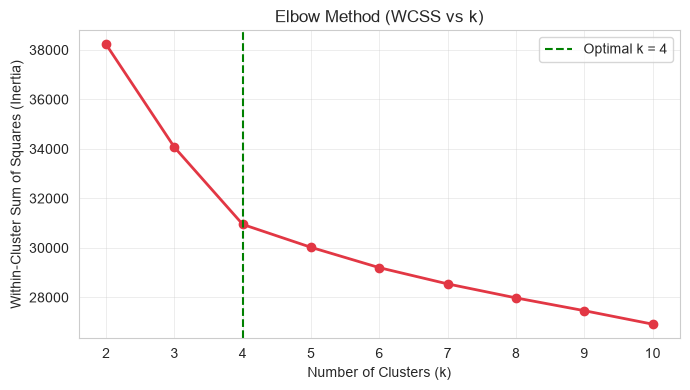

In [52]:
wcss = []
K_range = range(2, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_z_pca)
    wcss.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(list(K_range), wcss, marker='o', color='#e23744', linewidth=2)
plt.axvline(4, color='green', linestyle='--', label='Optimal k = 4')
plt.title('Elbow Method (WCSS vs k)')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-Cluster Sum of Squares (Inertia)')
plt.legend()
plt.tight_layout()
plt.show()

**Part 2 – Q4 (b): K-Means Clustering & Segment Interpretation

User Distribution Across Clusters:
         User_Count  Share_%
Cluster                     
0               782    21.80
1               677    18.87
2               934    26.04
3              1194    33.29

Cluster Mean Profiles:
Cluster                          0       1        2        3
app_opens_per_month          64.60    6.29    17.55    34.69
orders_per_month             18.05    1.35     3.86     8.92
avg_order_value             420.72  220.42   258.68   316.72
monthly_food_spend         7652.17  401.34  1035.98  2831.55
discount_usage_rate           0.25    0.29     0.55     0.34
promo_orders_ratio            0.30    0.43     0.66     0.40
days_since_last_order         3.20   44.75    15.58     7.11
avg_delivery_time_minutes    32.40   32.18    31.74    31.75
order_cancellation_rate       0.06    0.06     0.06     0.06
customer_support_chats        0.59    0.56     0.65     0.60
app_rating_given              4.10    4.10     4.14     4.08


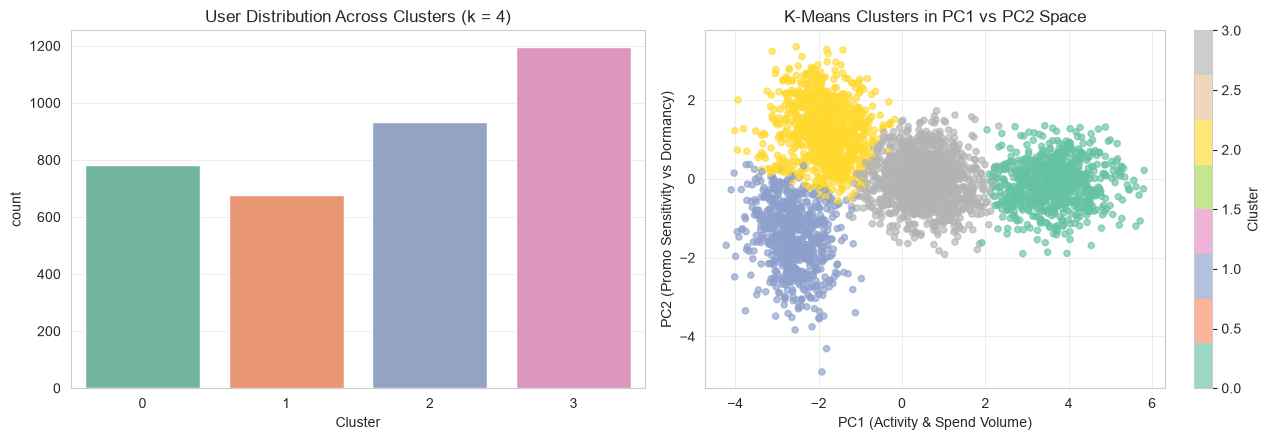

In [53]:
kmeans_final = KMeans(n_clusters=4, random_state=42, n_init=10)
df_z_clean['Cluster'] = kmeans_final.fit_predict(X_z_pca)

cluster_counts = df_z_clean['Cluster'].value_counts().sort_index()
print("User Distribution Across Clusters:")
print(pd.DataFrame({'User_Count': cluster_counts, 'Share_%': (cluster_counts / len(df_z_clean) * 100).round(2)}))

profile_cols = [
    'app_opens_per_month', 'orders_per_month', 'avg_order_value', 'monthly_food_spend',
    'discount_usage_rate', 'promo_orders_ratio', 'days_since_last_order',
    'avg_delivery_time_minutes', 'order_cancellation_rate', 'customer_support_chats', 'app_rating_given'
]
print("\nCluster Mean Profiles:")
print(df_z_clean.groupby('Cluster')[profile_cols].mean().round(2).T)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=df_z_clean, x='Cluster', palette='Set2', ax=axes[0])
axes[0].set_title('User Distribution Across Clusters (k = 4)')

scatter = axes[1].scatter(X_z_pca[:, 0], X_z_pca[:, 1], c=df_z_clean['Cluster'], cmap='Set2', alpha=0.65, s=20)
axes[1].set_title('K-Means Clusters in PC1 vs PC2 Space')
axes[1].set_xlabel('PC1 (Activity & Spend Volume)')
axes[1].set_ylabel('PC2 (Promo Sensitivity vs Dormancy)')
plt.colorbar(scatter, ax=axes[1], label='Cluster')

plt.tight_layout()
plt.show()